In [1]:
import getpass

import pandas as pd
import psycopg
import matplotlib.pyplot as plt

print("Health Metrics Analytics — Environment Ready")

Health Metrics Analytics — Environment Ready


In [2]:
password = getpass.getpass("PostgreSQL password: ")

conn = psycopg.connect(
    host="127.0.0.1",
    port=15432,
    dbname="health_metrics",
    user="health_analyst",
    password=password,
    sslmode="require",
    connect_timeout=10,
)

print("Connected to Ichabod PostgreSQL")

Connected to Ichabod PostgreSQL


In [3]:
query = """
SELECT
    timestamp_utc,
    hostname,
    cpu_percent,
    memory_used_mb,
    memory_available_mb,
    disk_used_percent,
    uptime_seconds
FROM public.system_observations
ORDER BY timestamp_utc;
"""

with conn.cursor() as cur:
    cur.execute(query)
    columns = [column.name for column in cur.description]
    rows = cur.fetchall()

df = pd.DataFrame(rows, columns=columns)

print(f"Observations retrieved: {len(df):,}")
df.head()

Observations retrieved: 577


,timestamp_utc,hostname,cpu_percent,memory_used_mb,memory_available_mb,disk_used_percent,uptime_seconds
0,2026-10-13 00:03:36.985762+00:00,ichabod,0.0,704.49,7323.68,7.4,148969
1,2026-10-13 00:07:44.184341+00:00,ichabod,0.0,684.66,7343.51,7.4,149217
2,2026-10-13 00:09:28.157854+00:00,ichabod,0.1,678.49,7349.68,7.4,149321
3,2026-10-13 00:14:43.046639+00:00,ichabod,0.0,689.86,7338.32,7.4,149636
4,2026-10-13 00:19:58.153071+00:00,ichabod,0.0,685.48,7342.69,7.4,149951


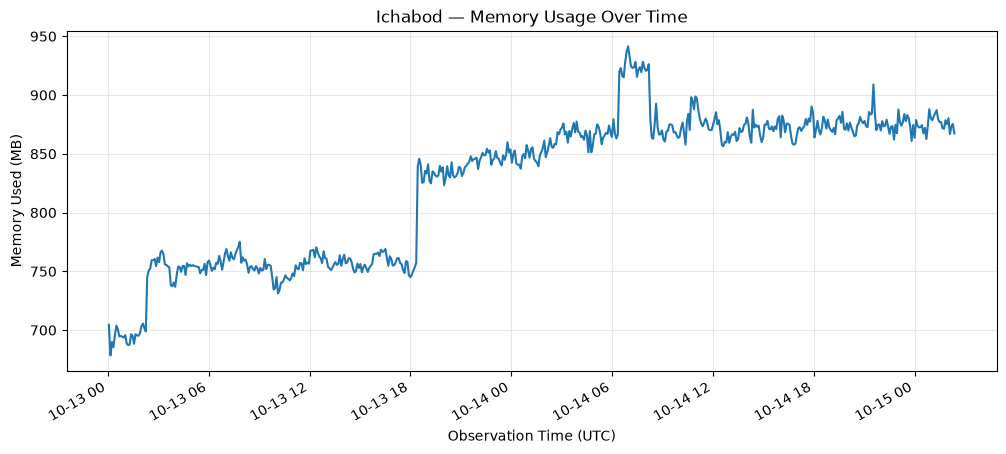

In [4]:
df["timestamp_utc"] = pd.to_datetime(df["timestamp_utc"], utc=True)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    df["timestamp_utc"],
    df["memory_used_mb"],
    linewidth=1.5,
)

ax.set_title("Ichabod — Memory Usage Over Time")
ax.set_xlabel("Observation Time (UTC)")
ax.set_ylabel("Memory Used (MB)")
ax.grid(True, alpha=0.3)

fig.autofmt_xdate()
plt.show()

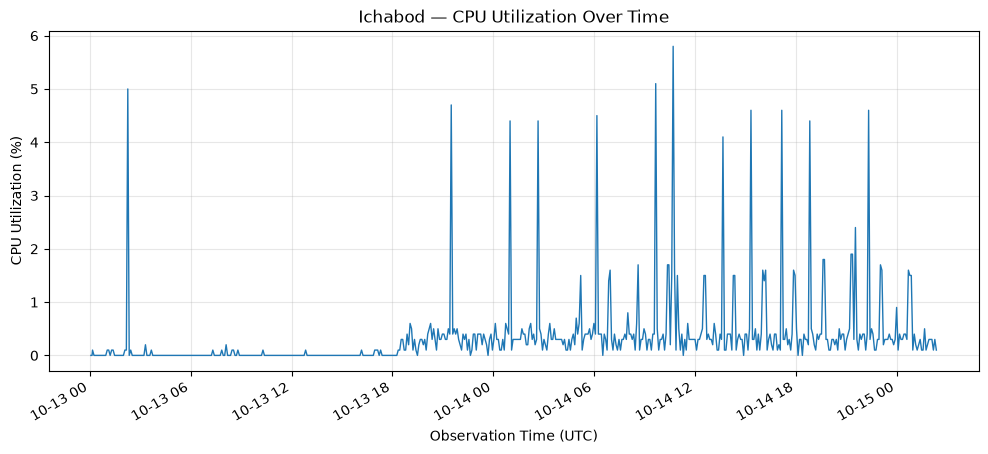

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    df["timestamp_utc"],
    df["cpu_percent"],
    linewidth=1,
)

ax.set_title("Ichabod — CPU Utilization Over Time")
ax.set_xlabel("Observation Time (UTC)")
ax.set_ylabel("CPU Utilization (%)")
ax.grid(True, alpha=0.3)

fig.autofmt_xdate()
plt.show()

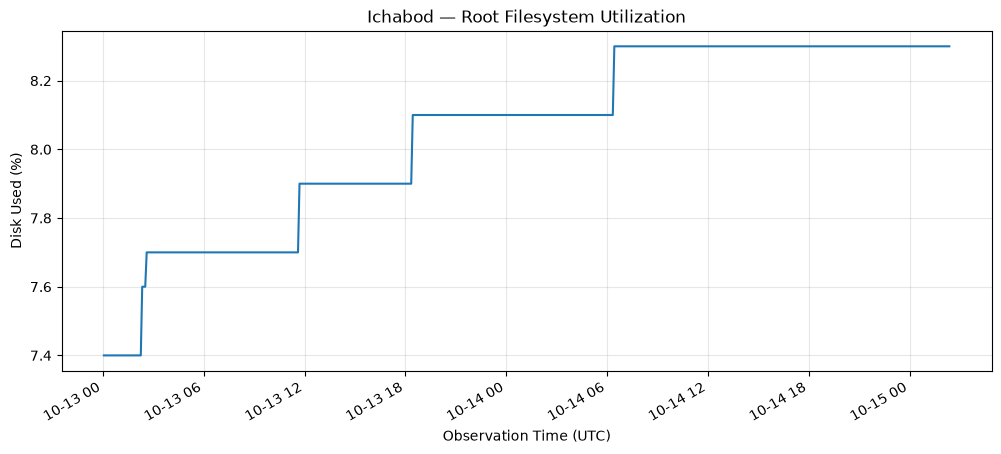

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    df["timestamp_utc"],
    df["disk_used_percent"],
    linewidth=1.5,
)

ax.set_title("Ichabod — Root Filesystem Utilization")
ax.set_xlabel("Observation Time (UTC)")
ax.set_ylabel("Disk Used (%)")
ax.grid(True, alpha=0.3)

fig.autofmt_xdate()
plt.show()

In [7]:
metrics = [
    "cpu_percent",
    "memory_used_mb",
    "memory_available_mb",
    "disk_used_percent",
    "uptime_seconds",
]

df[metrics].describe().round(2)

,cpu_percent,memory_used_mb,memory_available_mb,disk_used_percent,uptime_seconds
count,577.00,577.00,577.00,577.00,577.00
mean,0.35,823.98,7204.19,8.05,239371.78
std,0.73,61.76,61.76,0.27,52489.06
min,0.00,678.49,7086.71,7.40,148969.00
25%,0.00,757.36,7155.50,7.90,194017.00
50%,0.20,851.30,7176.88,8.10,239398.00
75%,0.40,872.67,7270.81,8.30,284677.00
max,5.80,941.47,7349.68,8.30,330061.00


In [8]:
df.isna().sum()

timestamp_utc          0
hostname               0
cpu_percent            0
memory_used_mb         0
memory_available_mb    0
disk_used_percent      0
uptime_seconds         0
dtype: int64

## Initial Analytical Findings

### Dataset

This analysis examines 577 system-health observations collected
from Ichabod between October 13 and October 14, 2026.

Observations were collected using Python and psutil, stored in
PostgreSQL, and retrieved securely through an SSH tunnel for
analysis using pandas and Matplotlib.

### CPU Utilization

Average sampled CPU utilization was 0.35%, with a maximum
observed value of 5.80%.

The measurements indicate low CPU utilization during sampled
intervals, suggesting capacity for additional workloads.

### Memory Utilization

Average reported memory usage was 823.98 MB, with a maximum
of 941.47 MB.

Memory consumption increased over the observation period,
including several noticeable step changes.

The cause of these changes has not yet been determined.

### Storage Utilization

Root filesystem utilization increased from approximately
7.4% to 8.3%.

Storage utilization remained low throughout the observation
period.

### Data Quality

All 577 retrieved observations contained values for the
seven collected fields.

Additional validation is required to assess timestamp
uniqueness, sampling consistency, and metric validity.

### Limitations

- CPU utilization is sampled periodically rather than continuously.
- The dataset covers a relatively short observation period.
- Memory usage does not independently establish memory pressure.
- Observed changes cannot yet be attributed to specific processes.
- The analysis currently covers only Ichabod.

### Conclusion

The initial analysis indicates that Ichabod is operating
with substantial available CPU, memory, and storage capacity
during the observed period.

The automated data pipeline provides a foundation for
longitudinal performance monitoring and future analytical
workloads.

In [9]:
conn.close()
print("PostgreSQL connection closed successfully.")

PostgreSQL connection closed successfully.
